<a href="https://colab.research.google.com/github/rafi1624/PCVK_18_Rafi-Abyantara/blob/main/Week%2010_Rafi%20Abyantara%20Pratama_18.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


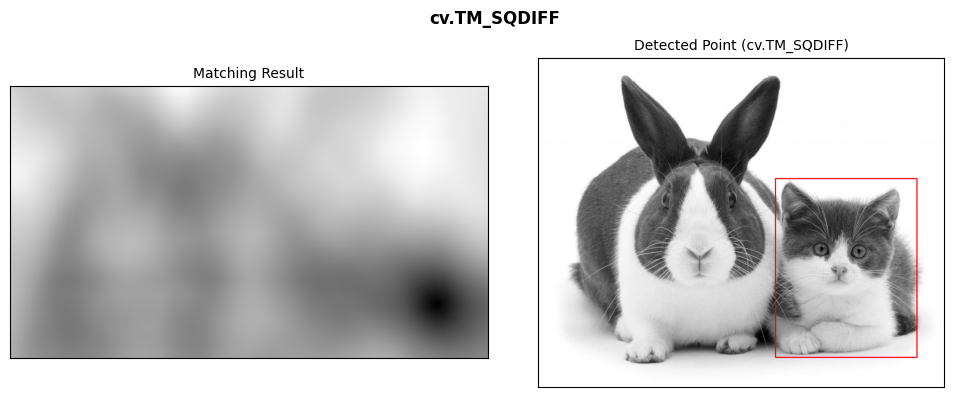

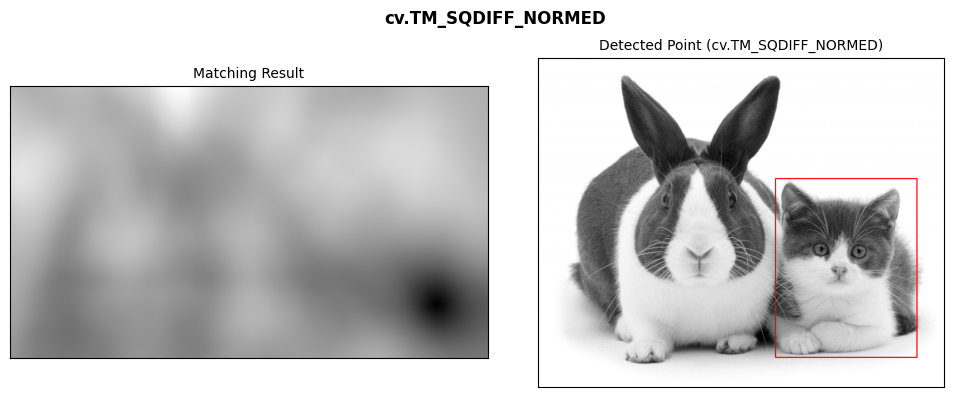

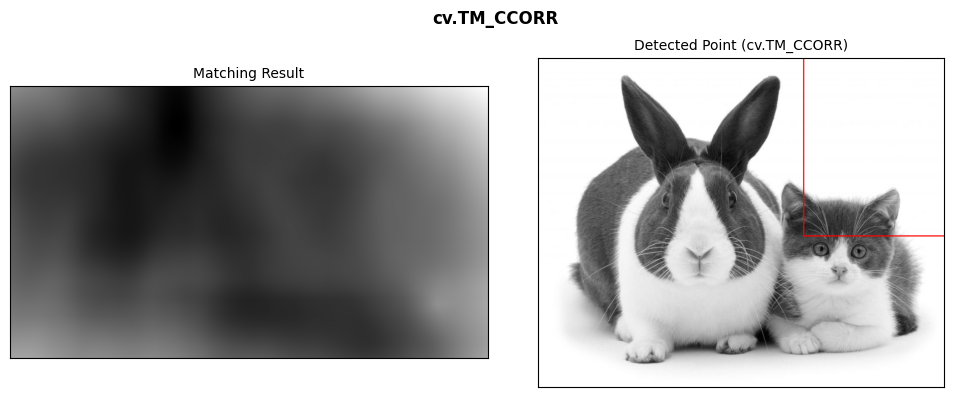

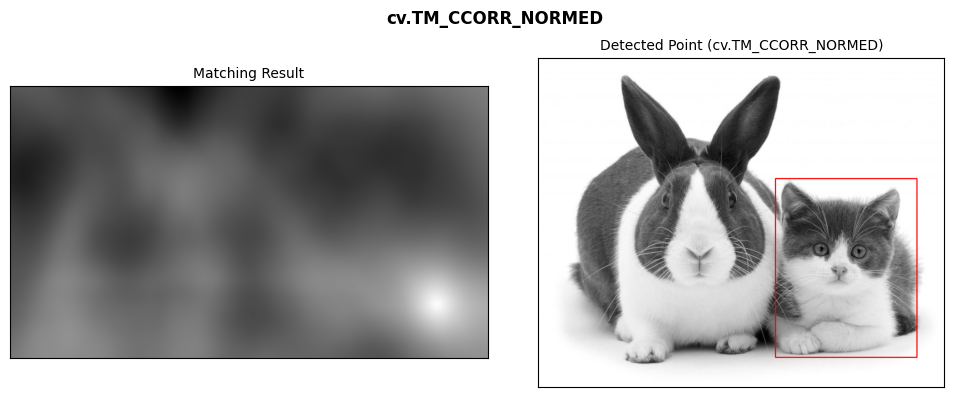

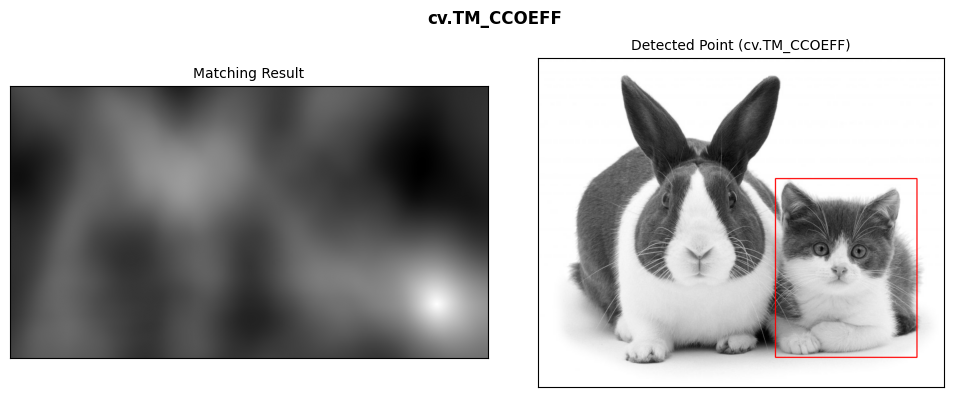

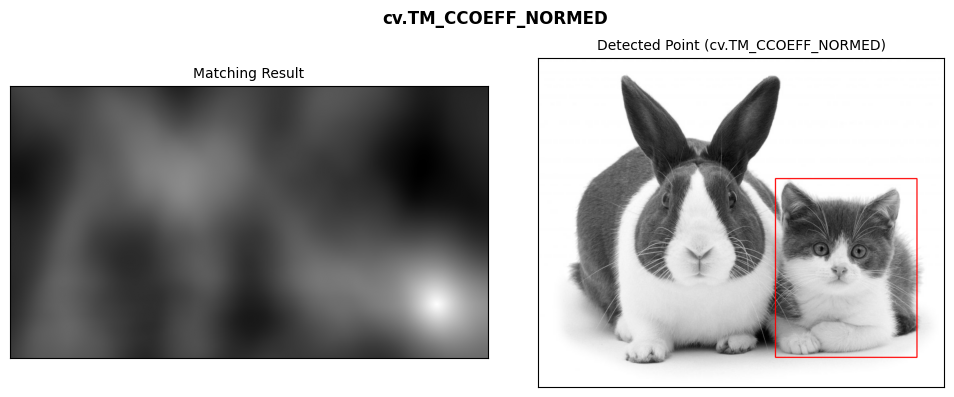

In [ ]:
# 1. Baca gambar input dan citra template (pastikan file sudah diunggah ke Google Drive/direktori kerja)
# Sesuaikan path direktori jika gambar disimpan di folder tertentu di Google Drive
img = cv.imread('/content/drive/MyDrive/PCVK/Images/Object Detection/cats_and_bunnies.jpg', cv.IMREAD_GRAYSCALE)
template = cv.imread('/content/drive/MyDrive/PCVK/Images/Object Detection/cat2_templatejpg.jpg', cv.IMREAD_GRAYSCALE)

# Cek apakah gambar berhasil dimuat
if img is None or template is None:
  print(
      'Error: Gambar tidak ditemukan. Pastikan nama file dan path sudah benar.'
  )
else:
  # Dapatkan ukuran tinggi dan lebar template
  w, h = template.shape[::-1]

  # 2. Daftar 6 metode template matching di OpenCV
  methods = [
      'cv.TM_SQDIFF',
      'cv.TM_SQDIFF_NORMED',
      'cv.TM_CCORR',
      'cv.TM_CCORR_NORMED',
      'cv.TM_CCOEFF',
      'cv.TM_CCOEFF_NORMED',
  ]

  # Loop untuk setiap metode
  for m_name in methods:
    # Salin gambar asli agar tidak tertimpa
    img_copy = img.copy()
    method = eval(m_name)

    # Lakukan template matching
    res = cv.matchTemplate(img_copy, template, method)
    min_val, max_val, min_loc, max_loc = cv.minMaxLoc(res)

    # Untuk metode SQDIFF dan SQDIFF_NORMED, nilai minimum adalah kecocokan terbaik
    # Untuk metode lainnya, nilai maksimum adalah kecocokan terbaik
    if method in [cv.TM_SQDIFF, cv.TM_SQDIFF_NORMED]:
      top_left = min_loc
    else:
      top_left = max_loc

    bottom_right = (top_left[0] + w, top_left[1] + h)

    # Buat persegi panjang merah pada titik yang terdeteksi
    # Konversi img_copy ke BGR agar kotak deteksi bisa berwarna merah
    img_display = cv.cvtColor(img, cv.COLOR_GRAY2BGR)
    cv.rectangle(img_display, top_left, bottom_right, (0, 0, 255), 2)

    # Tampilkan hasil menggunakan Matplotlib
    plt.figure(figsize=(10, 4))

    # Plot Hasil Matching (peta panas/heatmap)
    plt.subplot(1, 2, 1)
    plt.imshow(res, cmap='gray')
    plt.title('Matching Result', fontsize=10)
    plt.xticks([])
    plt.yticks([])

    # Plot Gambar Deteksi
    plt.subplot(1, 2, 2)
    plt.imshow(cv.cvtColor(img_display, cv.COLOR_BGR2RGB))
    plt.title(f'Detected Point ({m_name})', fontsize=10)
    plt.xticks([])
    plt.yticks([])

    plt.suptitle(m_name, fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.show()

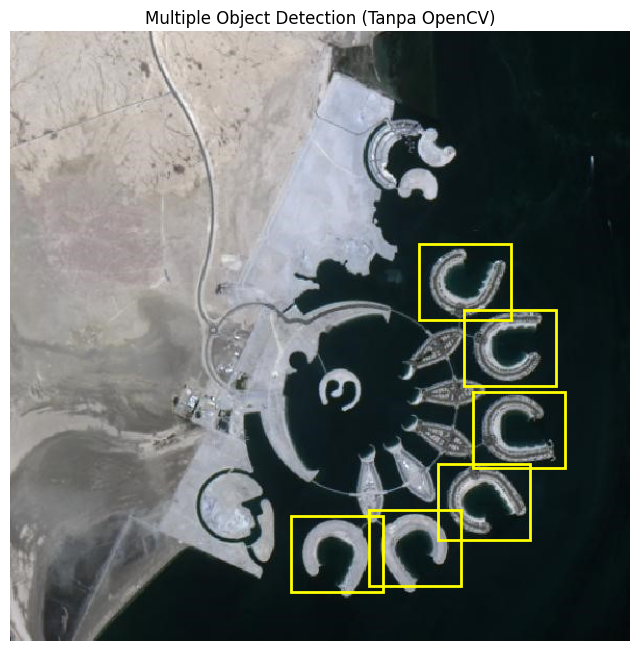

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np

# 1. Memuat citra input dan citra template (tanpa OpenCV)
img_path = '/content/drive/MyDrive/PCVK/Images/Object Detection/bahrain.jpg'
template_path = '/content/drive/MyDrive/PCVK/Images/Object Detection/bahrain-template.jpg'

# Baca gambar menggunakan matplotlib
img_rgb = plt.imread(img_path)
template_rgb = plt.imread(template_path)

# Konversi ke grayscale (jika citra berwarna RGB)
if img_rgb.ndim == 3:
  img = np.dot(img_rgb[..., :3], [0.2989, 0.5870, 0.1140])
else:
  img = img_rgb

if template_rgb.ndim == 3:
  template = np.dot(template_rgb[..., :3], [0.2989, 0.5870, 0.1140])
else:
  template = template_rgb

# Ubah tipe data menjadi float
img = img.astype(np.float32)
template = template.astype(np.float32)

h_t, w_t = template.shape
h_i, w_i = img.shape

# 2. Implementasi Normalized Cross-Correlation (NCC) secara manual
template_centered = template - np.mean(template)
template_norm = np.linalg.norm(template_centered)

result_h = h_i - h_t + 1
result_w = w_i - w_t + 1
result = np.zeros((result_h, result_w))

# Sliding window untuk mencocokkan template ke seluruh bagian gambar
for y in range(result_h):
  for x in range(result_w):
    patch = img[y : y + h_t, x : x + w_t]
    patch_centered = patch - np.mean(patch)
    patch_norm = np.linalg.norm(patch_centered)

    if patch_norm == 0 or template_norm == 0:
      result[y, x] = 0
    else:
      result[y, x] = np.sum(patch_centered * template_centered) / (
          patch_norm * template_norm
      )

# 3. Deteksi Multiple Object dengan Threshold yang disesuaikan & Filter Jarak
threshold = 0.45  # Anda bisa menaikkan/menurunkan nilai ini (rentang 0.40 - 0.55)
y_locs, x_locs = np.where(result >= threshold)

# Simpan skor dan koordinatnya
coordinates = []
for y, x in zip(y_locs, x_locs):
  score = result[y, x]
  coordinates.append((score, x, y))

# Urutkan dari skor kecocokan tertinggi ke terendah
coordinates.sort(key=lambda x: x[0], reverse=True)

# Filter agar kotak tidak menumpuk di objek yang sama (NMS Sederhana)
filtered_boxes = []
min_distance = (
    30  # Jarak minimum piksel antar objek agar tidak terdeteksi ganda
)

for score, x, y in coordinates:
  overlap = False
  for fx, fy in filtered_boxes:
    if abs(x - fx) < min_distance and abs(y - fy) < min_distance:
      overlap = True
      break
  if not overlap:
    filtered_boxes.append((x, y))

# 4. Visualisasi Hasil dengan Banyak Kotak Kuning
plt.figure(figsize=(8, 8))
if img_rgb.ndim == 3:
  plt.imshow(img_rgb)
else:
  plt.imshow(img_rgb, cmap='gray')

ax = plt.gca()

# Gambar kotak kuning untuk setiap objek yang lolos filter
for x, y in filtered_boxes:
  rect = patches.Rectangle(
      (x, y), w_t, h_t, linewidth=2, edgecolor='yellow', facecolor='none'
  )
  ax.add_patch(rect)

plt.title('Multiple Object Detection (Tanpa OpenCV)')
plt.axis('off')
plt.show()

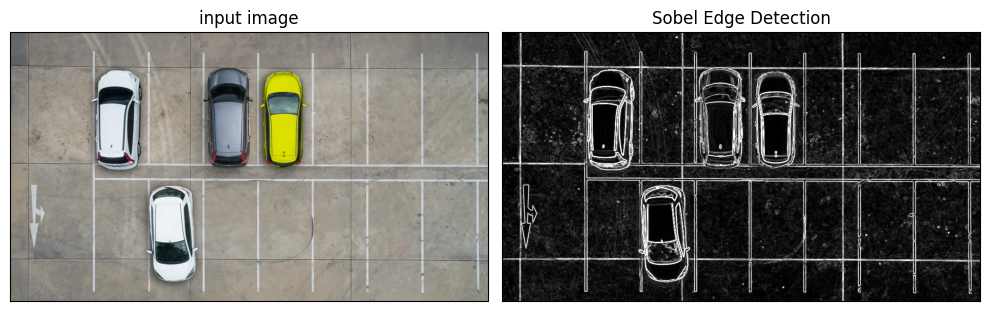

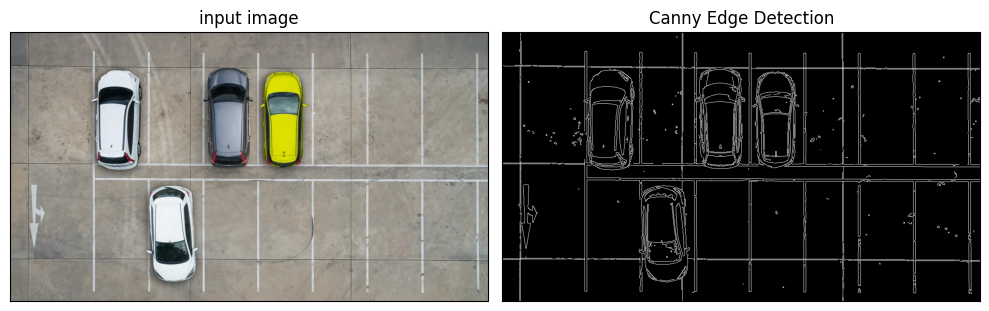

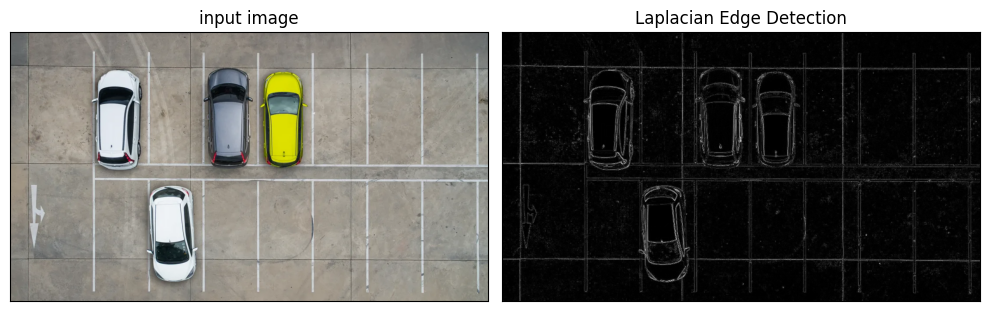

In [ ]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

# 1. Baca gambar 'car-park.jpg' dalam bentuk grayscale (keabuan)
# Pastikan path file sudah sesuai dengan direktori Google Drive Anda
img_path = '/content/drive/MyDrive/PCVK/Images/Object Detection/car-park.jpg'
img_gray = cv.imread(img_path, cv.IMREAD_GRAYSCALE)
img_rgb = cv.imread(
    img_path
)  # Untuk ditampilkan berwarna di sisi kiri jika diperlukan

if img_gray is None:
  print('Error: Gambar car-park.jpg tidak ditemukan. Periksa kembali path file.')
else:
  # ==========================================
  # a. SOBEL EDGE DETECTION
  # ==========================================
  # Hitung derivatif Sobel arah X dan Y
  sobelx = cv.Sobel(img_gray, cv.CV_64F, 1, 0, ksize=3)
  sobely = cv.Sobel(img_gray, cv.CV_64F, 0, 1, ksize=3)
  # Gabungkan magnitudo gradien
  sobel_combined = cv.magnitude(sobelx, sobely)
  sobel_combined = cv.convertScaleAbs(sobel_combined)

  # ==========================================
  # b. CANNY EDGE DETECTION
  # ==========================================
  # Parameter threshold 100 dan 200 dapat disesuaikan jika ingin garis lebih tipis/tebal
  canny_edges = cv.Canny(img_gray, 100, 200)

  # ==========================================
  # c. LAPLACIAN EDGE DETECTION
  # ==========================================
  laplacian = cv.Laplacian(img_gray, cv.CV_64F)
  laplacian_abs = cv.convertScaleAbs(laplacian)

  # ==========================================
  # VISUALISASI HASIL (Masing-masing metode 2 kolom: Asli/Hasil Deteksi)
  # ==========================================

  # 1. Plot Sobel
  plt.figure(figsize=(10, 4))
  plt.subplot(1, 2, 1)
  plt.imshow(cv.cvtColor(img_rgb, cv.COLOR_BGR2RGB))
  plt.title('input image')
  plt.xticks([])
  plt.yticks([])

  plt.subplot(1, 2, 2)
  plt.imshow(sobel_combined, cmap='gray')
  plt.title('Sobel Edge Detection')
  plt.xticks([])
  plt.yticks([])
  plt.tight_layout()
  plt.show()

  # 2. Plot Canny
  plt.figure(figsize=(10, 4))
  plt.subplot(1, 2, 1)
  plt.imshow(cv.cvtColor(img_rgb, cv.COLOR_BGR2RGB))
  plt.title('input image')
  plt.xticks([])
  plt.yticks([])

  plt.subplot(1, 2, 2)
  plt.imshow(canny_edges, cmap='gray')
  plt.title('Canny Edge Detection')
  plt.xticks([])
  plt.yticks([])
  plt.tight_layout()
  plt.show()

  # 3. Plot Laplacian
  plt.figure(figsize=(10, 4))
  plt.subplot(1, 2, 1)
  plt.imshow(cv.cvtColor(img_rgb, cv.COLOR_BGR2RGB))
  plt.title('input image')
  plt.xticks([])
  plt.yticks([])

  plt.subplot(1, 2, 2)
  plt.imshow(laplacian_abs, cmap='gray')
  plt.title('Laplacian Edge Detection')
  plt.xticks([])
  plt.yticks([])
  plt.tight_layout()
  plt.show()

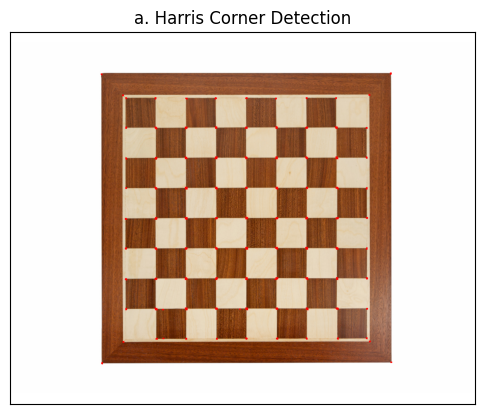

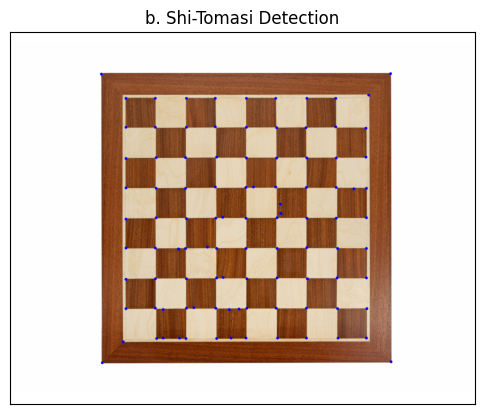

In [ ]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

# 1. Baca gambar 'chessboard.jpg'
# Pastikan path file sudah sesuai dengan direktori Google Drive Anda
img_path = '/content/drive/MyDrive/PCVK/Images/Object Detection/chess-board.jpg'
img = cv.imread(img_path)

if img is None:
  print('Error: Gambar chessboard.jpg tidak ditemukan. Periksa kembali path file.')
else:
  # Konversi ke citra grayscale dan float32 (diperlukan untuk algoritma corner detection)
  gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
  gray_float = np.float32(gray)

  # ==========================================
  # a. HARRIS CORNER DETECTION
  # ==========================================
  # Parameter: block_size=2, ksize=3, k=0.04
  dst = cv.cornerHarris(gray_float, 2, 3, 0.04)

  # Dilatasi untuk memperjelas titik sudut yang terdeteksi
  dst = cv.dilate(dst, None)

  # Salin gambar asli untuk menandai sudut Harris (warna merah)
  img_harris = img.copy()
  # Threshold untuk menandai sudut (nilai 0.01 * maksimum biasanya optimal)
  img_harris[dst > 0.01 * dst.max()] = [0, 0, 255]  # BGR: Merah

  # ==========================================
  # b. SHI-TOMASI CORNER DETECTION
  # ==========================================
  # cv.goodFeaturesToTrack menggunakan metode Shi-Tomasi secara default (k=0.04 atau minEigenVal)
  # maxCorners=100 (maksimal titik), qualityLevel=0.01, minDistance=10
  corners = cv.goodFeaturesToTrack(gray, 100, 0.01, 10)
  corners = corners.astype(int)

  # Salin gambar asli untuk menandai sudut Shi-Tomasi (warna biru/titik)
  img_shitomasi = img.copy()
  for i in corners:
    x, y = i.ravel()
    # Gambar lingkaran biru di setiap titik sudut
    cv.circle(img_shitomasi, (x, y), 3, (255, 0, 0), -1)  # BGR: Biru

  # ==========================================
  # VISUALISASI HASIL DENGAN MATPLOTLIB
  # ==========================================

  # 1. Plot Harris Corner Detection
  plt.figure(figsize=(6, 6))
  plt.imshow(cv.cvtColor(img_harris, cv.COLOR_BGR2RGB))
  plt.title('a. Harris Corner Detection')
  plt.xticks([])
  plt.yticks([])
  plt.show()

  # 2. Plot Shi-Tomasi Detection
  plt.figure(figsize=(6, 6))
  plt.imshow(cv.cvtColor(img_shitomasi, cv.COLOR_BGR2RGB))
  plt.title('b. Shi-Tomasi Detection')
  plt.xticks([])
  plt.yticks([])
  plt.show()

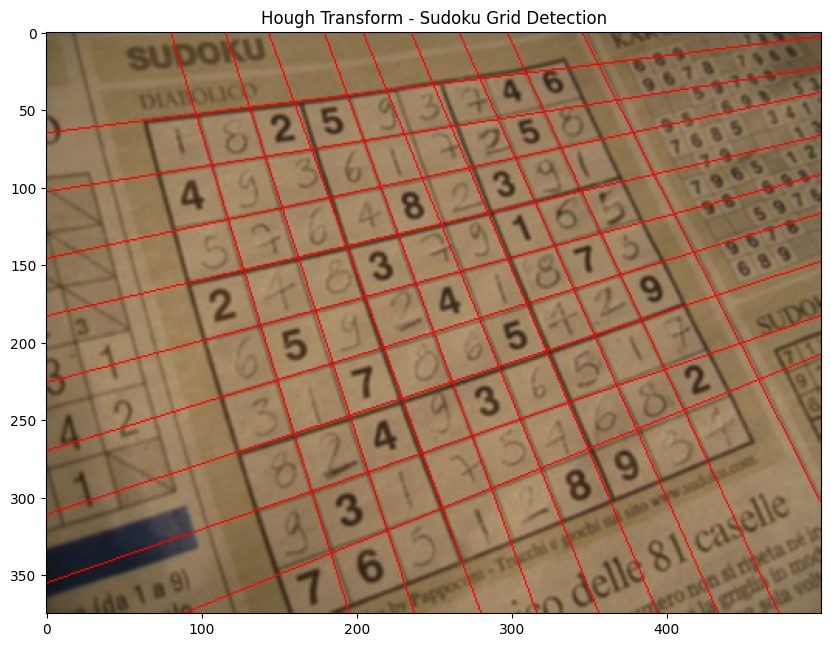

In [ ]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

# 1. Baca gambar 'sudoku.jpg' sesuai path Anda
img_path = '/content/drive/MyDrive/PCVK/Images/Object Detection/sudoku.jpg'
img = cv.imread(img_path)

if img is None:
  print('Error: Gambar sudoku.jpg tidak ditemukan. Periksa kembali path file.')
else:
  # Konversi ke grayscale
  gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

  # 2. Deteksi Tepi menggunakan Canny
  edges = cv.Canny(gray, 50, 150, apertureSize=3)

  # 3. Gunakan HoughLines standar
  lines = cv.HoughLines(edges, 1, np.pi / 180, 160)

  # 4. Filter garis agar tidak menumpuk/bergerombol (Non-Maximum Suppression sederhana)
  filtered_lines = []
  if lines is not None:
    for line in lines:
      rho, theta = line[0]
      # Cek apakah sudah ada garis dengan rho dan theta yang hampir sama
      is_duplicate = False
      for f_rho, f_theta in filtered_lines:
        # Jarak rho < 20 piksel dan selisih sudut < 0.1 radian dianggap garis yang sama
        if (
            abs(rho - f_rho) < 20 and abs(theta - f_theta) < 0.1
        ):
          is_duplicate = True
          break
      if not is_duplicate:
        filtered_lines.append((rho, theta))

  # Salin gambar asli untuk menggambar garis
  img_hough = img.copy()

  # 5. Gambar garis yang sudah difilter agar rapi dan tidak menumpuk
  for rho, theta in filtered_lines:
    a = np.cos(theta)
    b = np.sin(theta)
    x0 = a * rho
    y0 = b * rho

    # Buat titik agar garis melintang penuh
    x1 = int(round(x0 + 2000 * (-b)))
    y1 = int(round(y0 + 2000 * (a)))
    x2 = int(round(x0 - 2000 * (-b)))
    y2 = int(round(y0 - 2000 * (a)))

    # Gambar garis merah tipis
    cv.line(img_hough, (x1, y1), (x2, y2), (0, 0, 255), 1)

  # 6. Visualisasi Hasil Menggunakan Matplotlib
  plt.figure(figsize=(10, 10))
  plt.imshow(cv.cvtColor(img_hough, cv.COLOR_BGR2RGB))
  plt.title('Hough Transform - Sudoku Grid Detection')
  plt.axis('on')
  plt.show()

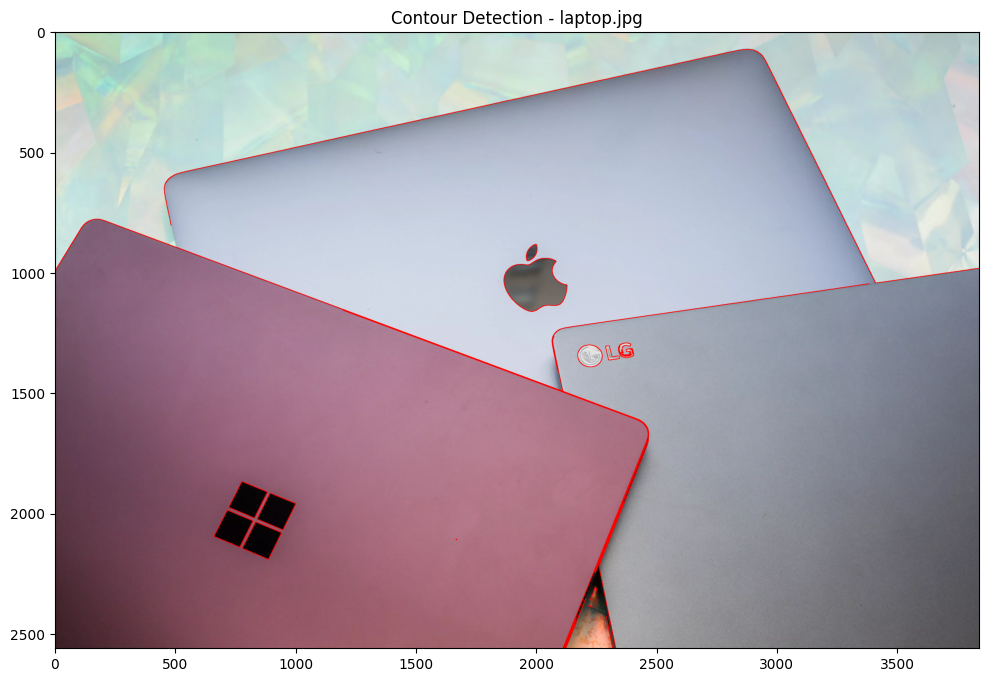

In [ ]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

# 1. Baca gambar 'laptop.jpg' sesuai path Anda
img_path = '/content/drive/MyDrive/PCVK/Images/Object Detection/laptop.jpg'
img = cv.imread(img_path)

if img is None:
  print('Error: Gambar laptop.jpg tidak ditemukan. Periksa kembali path file.')
else:
  # 2. Konversi gambar ke grayscale
  gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

  # 3. Gunakan Gaussian Blur untuk meredam noise agar garis lebih halus
  blurred = cv.GaussianBlur(gray, (5, 5), 0)

  # 4. Gunakan Canny Edge Detection (Ganti thresholding biasa dengan Canny)
  # Nilai 50 dan 150 bisa disesuaikan jika garis kurang/terlalu tebal
  edged = cv.Canny(blurred, 50, 150)

  # 5. Implementasi fungsi findContours() menggunakan hasil Canny
  contours, hierarchy = cv.findContours(
      edged, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE
  )

  # Salin gambar asli untuk menggambar garis kontur
  img_contour = img.copy()

  # 6. Gambar kontur dengan warna merah (BGR: 0, 0, 255) dan ketebalan 2
  cv.drawContours(img_contour, contours, -1, (0, 0, 255), 2)

  # 7. Visualisasi Hasil Menggunakan Matplotlib
  plt.figure(figsize=(12, 8))
  plt.imshow(cv.cvtColor(img_contour, cv.COLOR_BGR2RGB))
  plt.title('Contour Detection - laptop.jpg')
  plt.axis('on')
  plt.show()

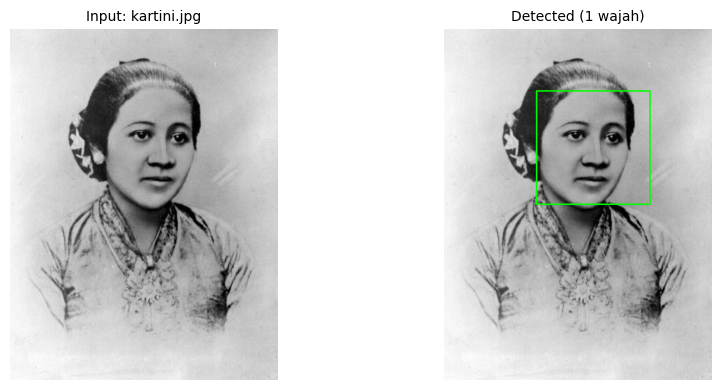

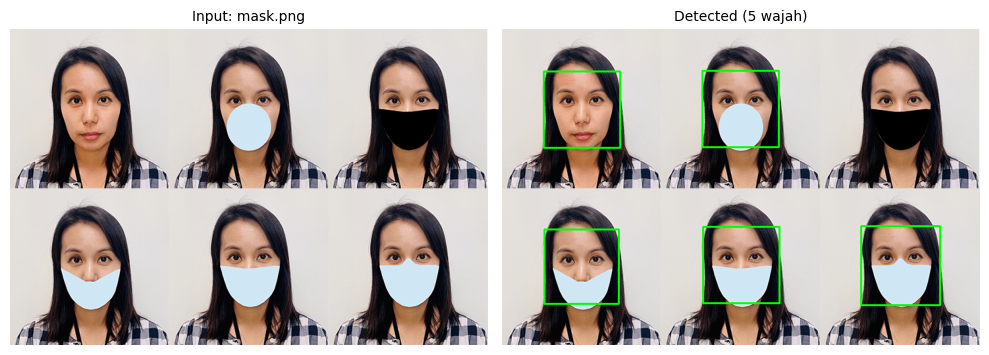

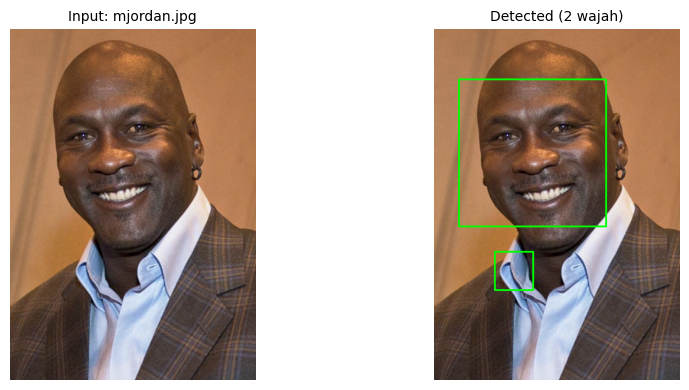

Peringatan: Gambar prabowo.jpg tidak ditemukan atau path salah.


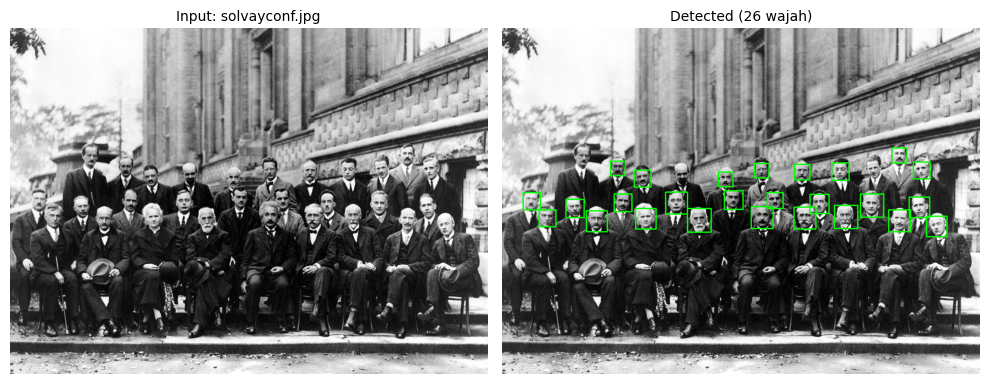

In [ ]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

# 1. Tentukan daftar nama file gambar yang ada di folder 'facedet' Anda
image_files = [
    'kartini.jpg',
    'mask.png',
    'mjordan.jpg',
    'prabowo.jpg',
    'solvayconf.jpg',
]

# Path folder utama di Google Drive Anda
base_path = '/content/drive/MyDrive/PCVK/Images/facedet/'

# 2. Muat pre-trained model Haar Cascade untuk deteksi wajah
face_cascade = cv.CascadeClassifier(
    cv.data.haarcascades + 'haarcascade_frontalface_default.xml'
)

# 3. Lakukan perulangan untuk setiap gambar
for file_name in image_files:
  img_path = base_path + file_name
  img = cv.imread(img_path)

  if img is None:
    print(f'Peringatan: Gambar {file_name} tidak ditemukan atau path salah.')
    continue

  # Konversi ke grayscale untuk proses deteksi
  gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

  # Parameter deteksi disesuaikan (minSize diperkecil agar wajah kecil/banyak seperti solvayconf tertangkap)
  faces = face_cascade.detectMultiScale(
      gray, scaleFactor=1.1, minNeighbors=5, minSize=(20, 20)
  )

  # Salin gambar untuk digambar kotak hijau
  img_result = img.copy()
  for x, y, w, h in faces:
    cv.rectangle(img_result, (x, y), (x + w, y + h), (0, 255, 0), 2)

  # Tampilkan berdampingan (Asli vs Hasil) menggunakan Matplotlib
  plt.figure(figsize=(10, 4))

  # Gambar Asli
  plt.subplot(1, 2, 1)
  plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
  plt.title(f'Input: {file_name}', fontsize=10)
  plt.axis('off')

  # Gambar Hasil Deteksi Wajah
  plt.subplot(1, 2, 2)
  plt.imshow(cv.cvtColor(img_result, cv.COLOR_BGR2RGB))
  plt.title(f'Detected ({len(faces)} wajah)', fontsize=10)
  plt.axis('off')

  plt.tight_layout()
  plt.show()

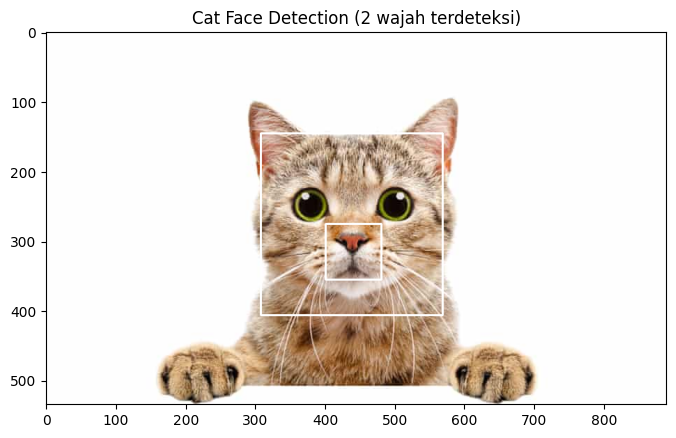

In [ ]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

# 1. Muat pre-trained model Haar Cascade khusus wajah kucing dari OpenCV
cat_face_cascade = cv.CascadeClassifier(
    cv.data.haarcascades + 'haarcascade_frontalcatface.xml'
)

# 2. Baca gambar kucing (sesuaikan path dan nama file gambar kucing Anda)
img_path = '/content/drive/MyDrive/PCVK/Images/facedet/kucing.jpg'
img = cv.imread(img_path)

if img is None:
  print('Error: Gambar kucing tidak ditemukan. Periksa kembali path file.')
else:
  # Konversi gambar ke grayscale (keabuan)
  gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

  # 3. Deteksi wajah kucing menggunakan detectMultiScale
  faces = cat_face_cascade.detectMultiScale(
      gray, scaleFactor=1.1, minNeighbors=3, minSize=(30, 30)
  )

  # Salin gambar asli untuk menggambar kotak (rectangle)
  img_result = img.copy()

  # 4. Buat kotak putih (atau hijau) pada area wajah kucing yang terdeteksi
  for x, y, w, h in faces:
    # Menggunakan warna putih (255, 255, 255) dengan ketebalan 2 sesuai contoh soal
    cv.rectangle(img_result, (x, y), (x + w, y + h), (255, 255, 255), 2)

  # 5. Visualisasi Hasil Menggunakan Matplotlib
  plt.figure(figsize=(8, 8))
  # Jika gambar aslinya berwarna, konversi BGR ke RGB; jika sudah grayscale tampilkan dengan cmap='gray'
  if len(img_result.shape) == 3:
    plt.imshow(cv.cvtColor(img_result, cv.COLOR_BGR2RGB))
  else:
    plt.imshow(img_result, cmap='gray')

  plt.title(f'Cat Face Detection ({len(faces)} wajah terdeteksi)')
  plt.axis('on')  # Menampilkan koordinat piksel di tepi gambar
  plt.show()

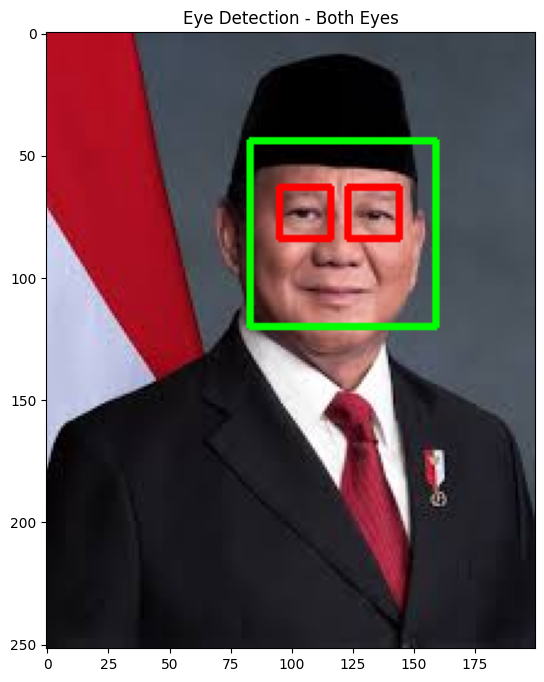

In [ ]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

# 1. Muat pre-trained model
face_cascade = cv.CascadeClassifier(
    cv.data.haarcascades + 'haarcascade_frontalface_default.xml'
)
eye_cascade = cv.CascadeClassifier(
    cv.data.haarcascades + 'haarcascade_eye.xml'
)

# 2. Baca gambar dan ubah ke grayscale langsung
img_path = '/content/drive/MyDrive/PCVK/Images/prabowo.jpg'
img = cv.imread(img_path)

if img is None:
  print('Error: Gambar prabowo.jpg tidak ditemukan.')
else:
  gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
  img_result = img.copy()

  # Deteksi wajah
  faces = face_cascade.detectMultiScale(
      gray, scaleFactor=1.05, minNeighbors=3, minSize=(30, 30)
  )

  for x, y, w, h in faces:
    # Batasi ROI hanya pada bagian atas wajah (area mata & alis) agar pencarian lebih fokus
    # y + int(h*0.15) sampai y + int(h*0.55)
    y1 = y + int(h * 0.15)
    y2 = y + int(h * 0.55)
    roi_gray = gray[y1:y2, x : x + w]

    # Deteksi mata dengan parameter yang lebih sensitif (minNeighbors lebih kecil)
    eyes = eye_cascade.detectMultiScale(
        roi_gray, scaleFactor=1.05, minNeighbors=2, minSize=(10, 10)
    )

    # Gambar kotak pada mata yang ditemukan
    for (ex, ey, ew, eh) in eyes:
      # Koordinat disesuaikan kembali terhadap gambar asli
      cv.rectangle(img_result, (x + ex, y1 + ey), (x + ex + ew, y1 + ey + eh), (0, 0, 255), 2)

    # Gambar kotak pada wajah (opsional, untuk memperjelas)
    cv.rectangle(img_result, (x, y), (x + w, y + h), (0, 255, 0), 2)

  # Visualisasi hasil
  plt.figure(figsize=(8, 8))
  plt.imshow(cv.cvtColor(img_result, cv.COLOR_BGR2RGB))
  plt.title('Eye Detection - Both Eyes')
  plt.axis('on')
  plt.show()

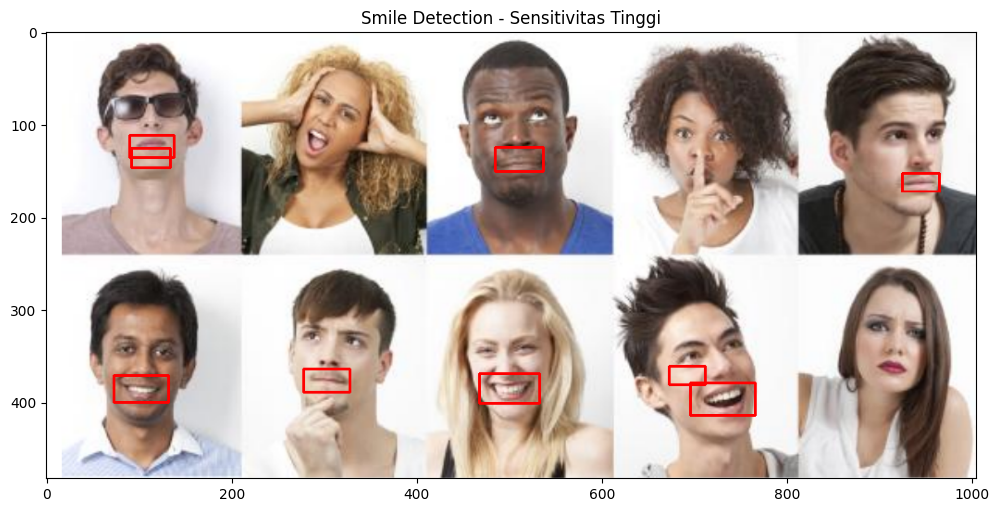

In [ ]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

# 1. Muat pre-trained model Haar Cascade untuk wajah dan senyuman
face_cascade = cv.CascadeClassifier(
    cv.data.haarcascades + 'haarcascade_frontalface_default.xml'
)
smile_cascade = cv.CascadeClassifier(
    cv.data.haarcascades + 'haarcascade_smile.xml'
)

# 2. Baca gambar kumpulan orang (sesuaikan path file Anda)
img_path = '/content/drive/MyDrive/PCVK/Images/facedet/people.png'
img = cv.imread(img_path)

if img is None:
  print('Error: Gambar people.jpg tidak ditemukan. Periksa kembali path file.')
else:
  gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
  img_result = img.copy()

  # Deteksi wajah dengan parameter yang lebih longgar
  faces = face_cascade.detectMultiScale(
      gray, scaleFactor=1.1, minNeighbors=3, minSize=(20, 20)
  )

  # 3. Deteksi senyuman dengan parameter yang sangat sensitif
  for x, y, w, h in faces:
    # Ambil area khusus bagian bawah wajah (area mulut/bibir)
    y1 = y + int(h * 0.5)
    roi_gray = gray[y1 : y + h, x : x + w]
    roi_color = img_result[y1 : y + h, x : x + w]

    # scaleFactor diturunkan ke 1.05 dan minNeighbors dikecilkan ke 3 agar lebih mudah mendeteksi senyum
    smiles = smile_cascade.detectMultiScale(
        roi_gray, scaleFactor=1.05, minNeighbors=3, minSize=(15, 15)
    )

    # Gambar kotak merah pada senyuman yang terdeteksi
    for sx, sy, sw, sh in smiles:
      cv.rectangle(roi_color, (sx, sy), (sx + sw, sy + sh), (0, 0, 255), 2)

  # 4. Visualisasi Hasil
  plt.figure(figsize=(12, 6))
  plt.imshow(cv.cvtColor(img_result, cv.COLOR_BGR2RGB))
  plt.title('Smile Detection - Sensitivitas Tinggi')
  plt.axis('on')
  plt.show()

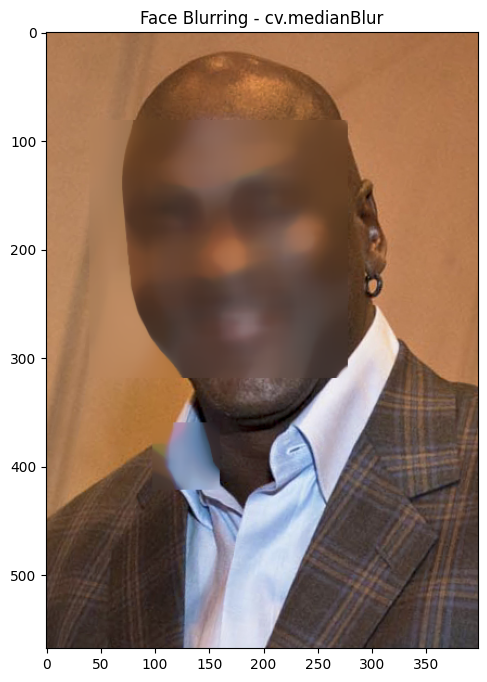

In [ ]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

# 1. Muat pre-trained model Haar Cascade untuk deteksi wajah
face_cascade = cv.CascadeClassifier(
    cv.data.haarcascades + 'haarcascade_frontalface_default.xml'
)

# 2. Baca gambar (contoh menggunakan 'mjordan.jpg', sesuaikan path file Anda)
img_path = '/content/drive/MyDrive/PCVK/Images/facedet/mjordan.jpg'
img = cv.imread(img_path)

if img is None:
  print('Error: Gambar tidak ditemukan. Periksa kembali path file.')
else:
  # Konversi ke grayscale untuk proses deteksi
  gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
  img_result = img.copy()

  # Deteksi wajah menggunakan detectMultiScale
  faces = face_cascade.detectMultiScale(
      gray, scaleFactor=1.1, minNeighbors=5, minSize=(30, 30)
  )

  # 3. Lakukan Blurring khusus pada area wajah yang terdeteksi (ROI)
  for x, y, w, h in faces:
    # Ambil potongan citra pada area wajah
    face_roi = img_result[y : y + h, x : x + w]

    # Terapkan cv.medianBlur (nilai kernel harus angka ganjil, misal 35 atau 45 agar blur tampak halus)
    blurred_face = cv.medianBlur(face_roi, 35)

    # Timpa kembali area wajah di gambar asli dengan hasil yang sudah diblur
    img_result[y : y + h, x : x + w] = blurred_face

  # 4. Visualisasi Hasil Menggunakan Matplotlib
  plt.figure(figsize=(8, 8))
  plt.imshow(cv.cvtColor(img_result, cv.COLOR_BGR2RGB))
  plt.title('Face Blurring - cv.medianBlur')
  plt.axis('on')
  plt.show()

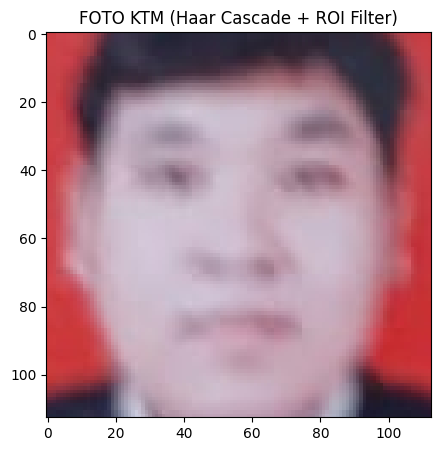

In [ ]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

# 1. Muat pre-trained model Haar Cascade untuk wajah
face_cascade = cv.CascadeClassifier(
    cv.data.haarcascades + 'haarcascade_frontalface_default.xml'
)

# 2. Baca gambar KTM Anda
img_path = '/content/drive/MyDrive/PCVK/Images/KTM Rafi.jpeg'
img = cv.imread(img_path)

if img is None:
  print('Error: Gambar KTM tidak ditemukan. Periksa kembali path file.')
else:
  h, w, _ = img.shape
  gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

  # 3. BATASI AREA (ROI): Potong dulu area kasar tempat foto KTM berada
  # (misalnya di bagian bawah kiri kartu, agar logo di atas tidak ikut terpindai)
  ymin, ymax = int(h * 0.50), int(h * 0.98)
  xmin, xmax = int(w * 0.0), int(w * 0.35)

  ktm_crop_area = gray[ymin:ymax, xmin:xmax]
  img_crop_color = img[ymin:ymax, xmin:xmax]

  # 4. Jalankan Haar Cascade hanya di dalam area foto KTM tersebut
  faces = face_cascade.detectMultiScale(
      ktm_crop_area, scaleFactor=1.05, minNeighbors=3, minSize=(20, 20)
  )

  if len(faces) > 0:
    for fx, fy, fw, fh in faces:
      # Ambil koordinat wajah yang ditemukan
      foto_ktm = img_crop_color[fy : fy + fh, fx : fx + fw]

      # 5. Visualisasi Hasil
      plt.figure(figsize=(5, 5))
      plt.imshow(cv.cvtColor(foto_ktm, cv.COLOR_BGR2RGB))
      plt.title('FOTO KTM (Haar Cascade + ROI Filter)')
      plt.axis('on')
      plt.show()
      break
  else:
    print('Wajah tidak ditemukan di area tersebut. Coba sesuaikan batas ROI.')